In [2]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

c:\Users\Ahmad Reza\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


In [12]:
df = pd.read_csv('CC GENERAL.csv')

In [13]:
df.head()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


In [14]:
print("Initial data shape:", df.shape)

Initial data shape: (8950, 18)


In [ ]:
customer_ids = df['CUST_ID']
features = df.drop('CUST_ID', axis=1)

In [16]:
print("Number of missing values in each column:")
print(features.isnull().sum())

Number of missing values in each column:
BALANCE                               0
BALANCE_FREQUENCY                     0
PURCHASES                             0
ONEOFF_PURCHASES                      0
INSTALLMENTS_PURCHASES                0
CASH_ADVANCE                          0
PURCHASES_FREQUENCY                   0
ONEOFF_PURCHASES_FREQUENCY            0
PURCHASES_INSTALLMENTS_FREQUENCY      0
CASH_ADVANCE_FREQUENCY                0
CASH_ADVANCE_TRX                      0
PURCHASES_TRX                         0
CREDIT_LIMIT                          1
PAYMENTS                              0
MINIMUM_PAYMENTS                    313
PRC_FULL_PAYMENT                      0
TENURE                                0
dtype: int64


In [27]:
features['MINIMUM_PAYMENTS'] = features['MINIMUM_PAYMENTS'].fillna(features['MINIMUM_PAYMENTS'].median())
features['CREDIT_LIMIT'] = features['CREDIT_LIMIT'].fillna(features['CREDIT_LIMIT'].median())

print("Missing values after pandas imputation:", features.isnull().sum().sum())

Missing values after pandas imputation: 0


In [28]:
# Scale the features
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

In [29]:
# Wrap the NumPy array back into a pandas DataFrame
scaled_features_df = pd.DataFrame(scaled_features, columns=features.columns)

# Now pandas methods will work perfectly
print("Missing values remaining:", scaled_features_df.isnull().sum().sum())
print("Scaled Data Shape:", scaled_features_df.shape)

# View the mathematical transformation
scaled_features_df.head(3)

Missing values remaining: 0
Scaled Data Shape: (8950, 17)


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,-0.731989,-0.249434,-0.424900,-0.356934,-0.349079,-0.466786,-0.806490,-0.678661,-0.707313,-0.675349,-0.476070,-0.511333,-0.960378,-0.528979,-0.302400,-0.525551,0.36068
1,0.786961,0.134325,-0.469552,-0.356934,-0.454576,2.605605,-1.221758,-0.678661,-0.916995,0.573963,0.110074,-0.591796,0.688678,0.818642,0.097500,0.234227,0.36068
2,0.447135,0.518084,-0.107668,0.108889,-0.454576,-0.466786,1.269843,2.673451,-0.916995,-0.675349,-0.476070,-0.109020,0.826100,-0.383805,-0.093293,-0.525551,0.36068


In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

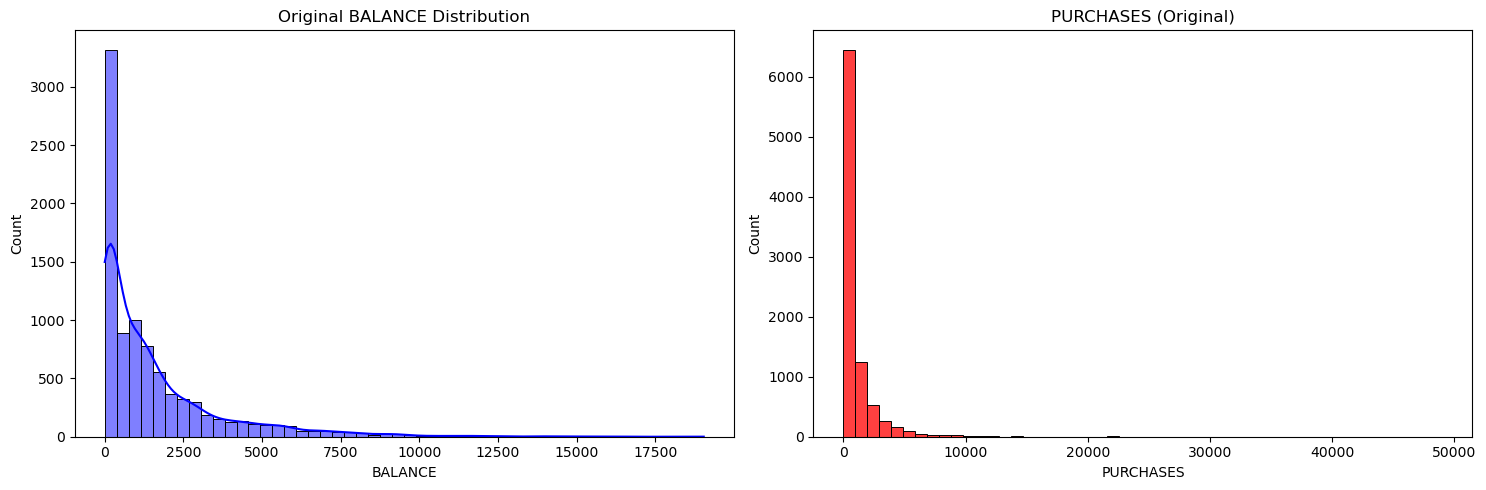

In [31]:
# Visualize the distribution of a few features before and after scaling
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(features['BALANCE'], bins=50, kde=True, ax=axes[0], color='blue').set(title='Original BALANCE Distribution')
sns.histplot(features['PURCHASES'], bins=50, ax=axes[1], color='red').set_title("PURCHASES (Original)")
plt.tight_layout()
plt.show()

In [ ]:
# CORPORATE OUTLIER TREATMENT: 99th Percentile Capping
# We create a copy so we don't destroy our original raw data
features_capped = features.copy()

for col in features_capped.columns:
    # Find the 99th percentile value for this specific column
    upper_limit = features_capped[col].quantile(0.99)
    # If a value is greater than the limit, replace it with the limit. Otherwise, keep it.
    features_capped[col] = np.where(features_capped[col] > upper_limit, upper_limit, features_capped[col])

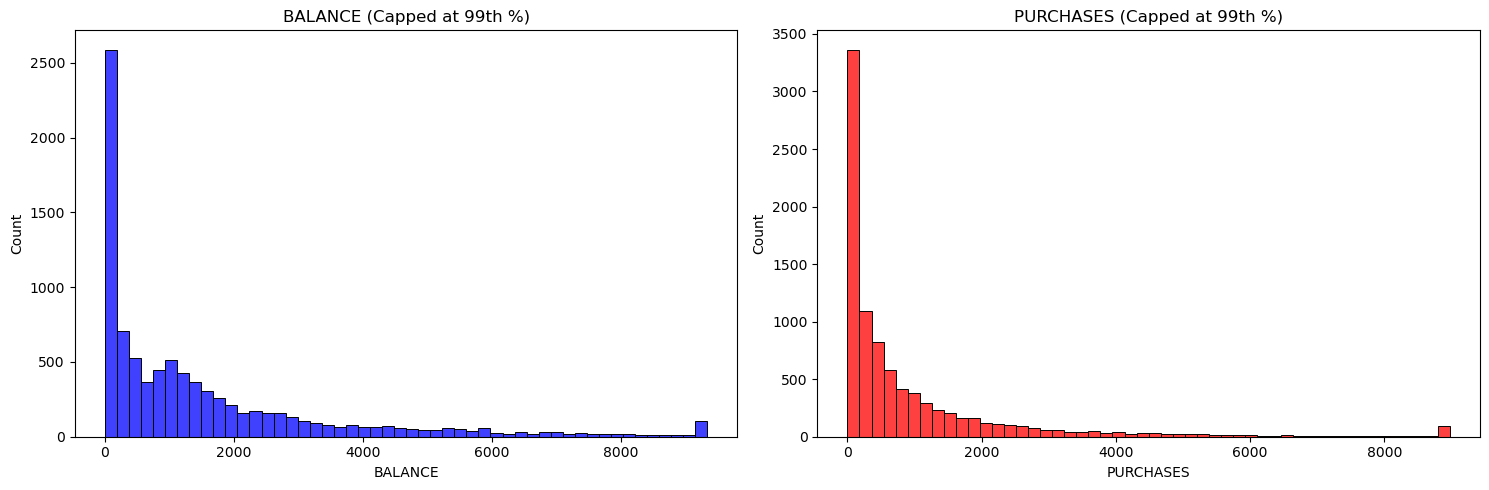

In [ ]:
# VISUALIZE THE FIX (AFTER CAPPING)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(features_capped['BALANCE'], bins=50, ax=axes[0], color='blue').set_title("BALANCE (Capped at 99th %)")
sns.histplot(features_capped['PURCHASES'], bins=50, ax=axes[1], color='red').set_title("PURCHASES (Capped at 99th %)")
plt.tight_layout()
plt.show()

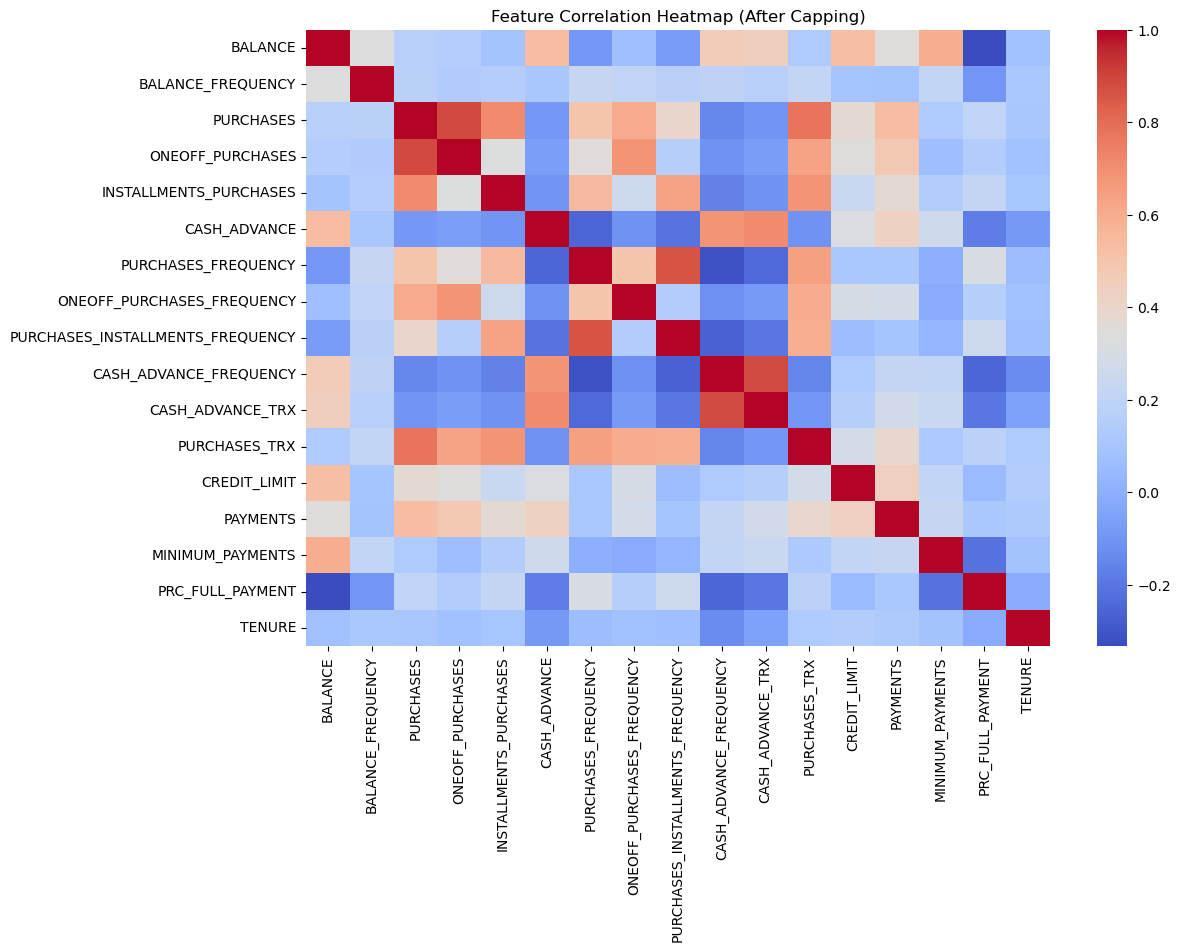

In [35]:
from sklearn.decomposition import PCA

# RESCALE THE CAPPED DATA
scaler = StandardScaler()
# Notice we fit on features_capped, not the original features
scaled_capped_array = scaler.fit_transform(features_capped)
scaled_features_df = pd.DataFrame(scaled_capped_array, columns=features_capped.columns)

# CORPORATE EDA: Correlation Heatmap (using capped data)
plt.figure(figsize=(12, 8))
sns.heatmap(features_capped.corr(), cmap='coolwarm', annot=False, fmt=".1f")
plt.title("Feature Correlation Heatmap (After Capping)")
plt.show()

In [36]:
# PRINCIPAL COMPONENT ANALYSIS (PCA)
pca = PCA()
pca.fit(scaled_features_df)

# Calculate how much information (variance) each component holds
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

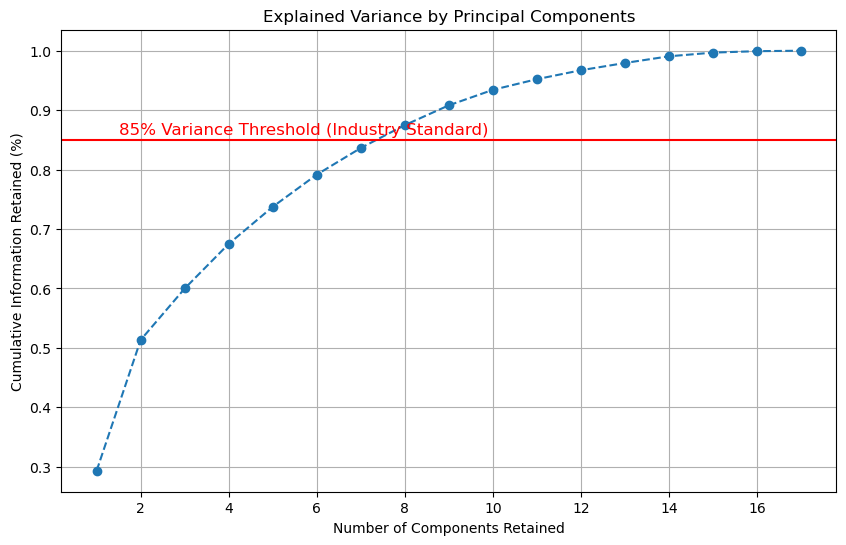

In [38]:
# THE ELBOW PLOT
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--')
plt.title('Explained Variance by Principal Components')
plt.xlabel('Number of Components Retained')
plt.ylabel('Cumulative Information Retained (%)')

# Draw a red line at 85% - the industry standard for dimensionality reduction
plt.axhline(y=0.85, color='r', linestyle='-') 
plt.text(1.5, 0.86, '85% Variance Threshold (Industry Standard)', color='red', fontsize=12)
plt.grid(True)
plt.show()

In [39]:
# 1. Programmatically dynamically find the crossing point 
# (Or you can hardcode n_components=8 based on our visual inspection)
optimal_components = np.argmax(cumulative_variance >= 0.85) + 1
print(f"Optimal components to retain 85% variance: {optimal_components}")

# 2. Re-instantiate and fit PCA with exactly 8 components
pca_final = PCA(n_components=optimal_components)
pca_features_array = pca_final.fit_transform(scaled_features_df)

# 3. Wrap the results into a clean pandas DataFrame for K-Means
pca_df = pd.DataFrame(
        pca_features_array, 
        columns=[f'PC{i}' for i in range(1, optimal_components + 1)]
)

print("PCA Extraction Complete. Compressed Dataset Shape:", pca_df.shape)
print("\nFirst 3 rows of the compressed mathematical space:")
print(pca_df.head(3))

Optimal components to retain 85% variance: 8
PCA Extraction Complete. Compressed Dataset Shape: (8950, 8)

First 3 rows of the compressed mathematical space:
        PC1       PC2       PC3       PC4       PC5       PC6       PC7  \
0 -1.769675 -1.412276 -0.205504  0.702749  0.022226  0.122817 -0.694922   
1 -1.523625  2.715729 -0.593406 -0.307722 -1.339520  0.567825  0.594596   
2  1.032048 -0.293420 -0.905297  1.528804  1.505356  0.459121  1.424659   

        PC8  
0  0.158287  
1  0.263040  
2 -1.000559  


Training K-Means models for k=2 through k=10. This may take a few seconds...


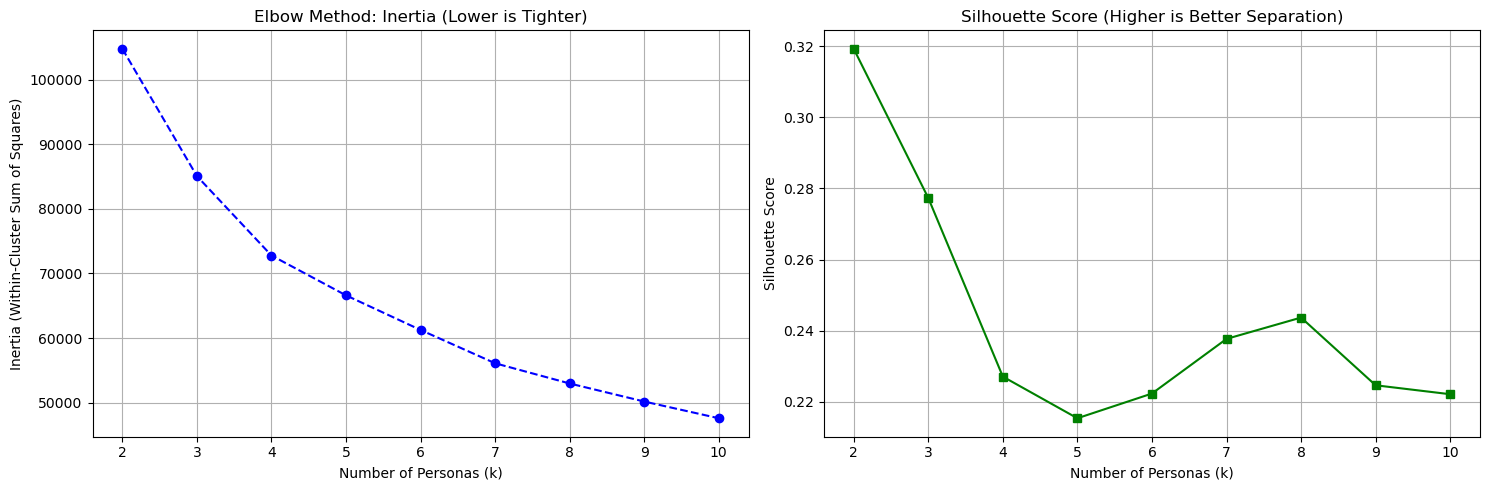

In [40]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# 1. Initialize lists to store our validation metrics
inertia_values = []
silhouette_scores = []
k_range = range(2, 11) # Testing 2 to 10 distinct customer personas

print("Training K-Means models for k=2 through k=10. This may take a few seconds...")

# 2. Loop through and train a model for each k
for k in k_range:
    # random_state=42 ensures exact reproducibility for stakeholder review
    # n_init=10 explicitly sets the number of centroid initializations 
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(pca_df)
    
    inertia_values.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(pca_df, kmeans.labels_))

# 3. Plot the results side-by-side for executive review
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Inertia (Looking for the Elbow)
axes[0].plot(k_range, inertia_values, marker='o', color='blue', linestyle='--')
axes[0].set_title('Elbow Method: Inertia (Lower is Tighter)')
axes[0].set_xlabel('Number of Personas (k)')
axes[0].set_ylabel('Inertia (Within-Cluster Sum of Squares)')
axes[0].grid(True)

# Plot 2: Silhouette Score (Looking for the Peak)
axes[1].plot(k_range, silhouette_scores, marker='s', color='green', linestyle='-')
axes[1].set_title('Silhouette Score (Higher is Better Separation)')
axes[1].set_xlabel('Number of Personas (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [42]:
# 1. Fit the final K-Means model with our strategic choice of 4 personas
final_kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
final_kmeans.fit(pca_df)

# 2. Attach the cluster labels to our ORIGINAL, unscaled dataset
# Why original? Because stakeholders want to see "$5,000 Balance", not "-0.45 PC1"
# We also bring back the CUST_ID we saved in Phase 1 for the final deployment
final_data = features.copy()
final_data['CUST_ID'] = customer_ids
final_data['PERSONA_ID'] = final_kmeans.labels_

# 3. Profiling the Personas: Calculate the average behavior of each cluster
persona_summary = final_data.groupby('PERSONA_ID').mean(numeric_only=True).round(2)

# Let's inspect the defining characteristics of these 4 groups
defining_columns = [
    'BALANCE', 
    'PURCHASES', 
    'CASH_ADVANCE', 
    'MINIMUM_PAYMENTS', 
    'PRC_FULL_PAYMENT', 
    'CREDIT_LIMIT'
]

print("Average Customer Behavior by Persona:")
print(persona_summary[defining_columns])

Average Customer Behavior by Persona:
            BALANCE  PURCHASES  CASH_ADVANCE  MINIMUM_PAYMENTS  \
PERSONA_ID                                                       
0            974.00     264.06        549.73            529.78   
1            807.05    1046.00        179.31            660.09   
2           4396.79     424.61       4340.13           1893.95   
3           2966.04    5955.00        706.24           1475.33   

            PRC_FULL_PAYMENT  CREDIT_LIMIT  
PERSONA_ID                                  
0                       0.08       3219.24  
1                       0.27       3971.87  
2                       0.04       7244.09  
3                       0.28       8792.31  


In [43]:
import pandas as pd

# Export the finalized dataset with CUST_ID and PERSONA_ID
export_filename = 'customer_personas_final.csv'
final_data.to_csv(export_filename, index=False)

print(f"Phase 1 Complete! Enriched dataset successfully exported to: {export_filename}")
print(final_data[['CUST_ID', 'PERSONA_ID', 'BALANCE', 'PURCHASES']].head())

Phase 1 Complete! Enriched dataset successfully exported to: customer_personas_final.csv
  CUST_ID  PERSONA_ID      BALANCE  PURCHASES
0  C10001           0    40.900749      95.40
1  C10002           2  3202.467416       0.00
2  C10003           1  2495.148862     773.17
3  C10004           0  1666.670542    1499.00
4  C10005           0   817.714335      16.00
